In [ ]:

%run run_epl_models_colab.py


Majority-class baseline {'Model': 'Majority-class baseline', 'Test accuracy': 0.424, 'Macro F1': 0.1985, 'Correct': 159, 'Test matches': 375}
              precision    recall  f1-score   support

           A       0.00      0.00      0.00       114
           D       0.00      0.00      0.00       102
           H       0.42      1.00      0.60       159

    accuracy                           0.42       375
   macro avg       0.14      0.33      0.20       375
weighted avg       0.18      0.42      0.25       375

Multinomial logistic regression {'Model': 'Multinomial logistic regression', 'Test accuracy': 0.4667, 'Macro F1': 0.3514, 'Correct': 175, 'Test matches': 375}
              precision    recall  f1-score   support

           A       0.44      0.45      0.44       114
           D       0.50      0.01      0.02       102
           H       0.48      0.77      0.59       159

    accuracy                           0.47       375
   macro avg       0.47      0.41      0.35   

In [ ]:

import pandas as pd

df = pd.read_csv("EPL_Combined_1900_Matches.csv")

print("Total matches:", len(df))
print("\nColumns:")
print(df.columns.tolist())

print("\nFirst 5 matches:")
display(df.head())

print("\nMatch results:")
print(df["FTR"].value_counts())


Total matches: 1900

Columns:
['Date', 'HomeTeam', 'AwayTeam', 'FTHG', 'FTAG', 'FTR', 'Season']

First 5 matches:


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,Season
0,13/08/2021,Brentford,Arsenal,2,0,H,2021–22
1,14/08/2021,Man United,Leeds,5,1,H,2021–22
2,14/08/2021,Burnley,Brighton,1,2,A,2021–22
3,14/08/2021,Chelsea,Crystal Palace,3,0,H,2021–22
4,14/08/2021,Everton,Southampton,3,1,H,2021–22



Match results:
FTR
H    839
A    607
D    454
Name: count, dtype: int64


In [10]:

# Count the three possible results
counts = df["FTR"].value_counts()

# Convert counts into percentages
percentages = df["FTR"].value_counts(normalize=True) * 100

# Put everything into a table
summary = pd.DataFrame({
    "Matches": counts,
    "Percentage": percentages.round(2)
})

print(summary)


     Matches  Percentage
FTR                     
H        839       44.16
A        607       31.95
D        454       23.89


Total matches: 1900

Matches per season:
Season
2021–22    380
2022–23    380
2023–24    380
2024–25    380
2025–26    380
Name: count, dtype: int64


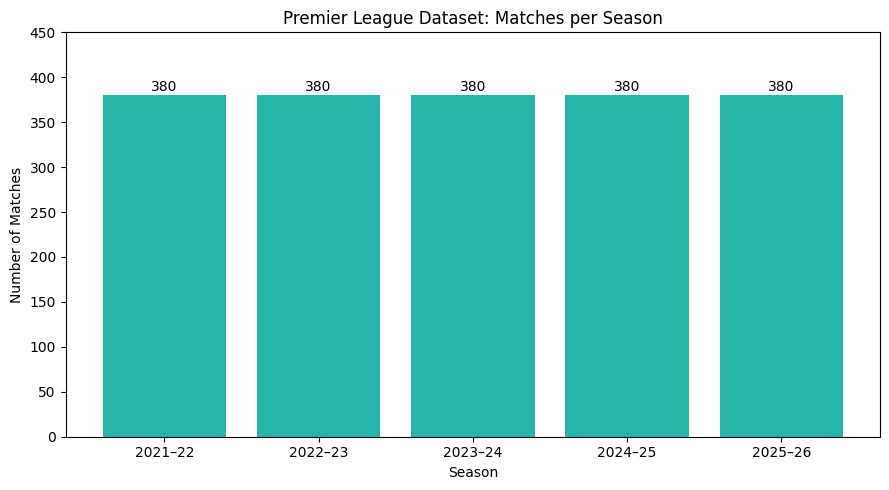

In [17]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Load our actual dataset
df = pd.read_csv("EPL_Combined_1900_Matches.csv")

# Count matches in each season
season_counts = df["Season"].value_counts().sort_index()

print("Total matches:", len(df))
print("\nMatches per season:")
print(season_counts)

# Create the chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    season_counts.index,
    season_counts.values,
    color="#25B5A9"
)

ax.set_title("Premier League Dataset: Matches per Season")
ax.set_xlabel("Season")
ax.set_ylabel("Number of Matches")
ax.set_ylim(0, 450)

for bar in bars:
    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 5,
        str(int(bar.get_height())),
        ha="center"
    )

plt.tight_layout()
display(fig)
plt.close(fig)


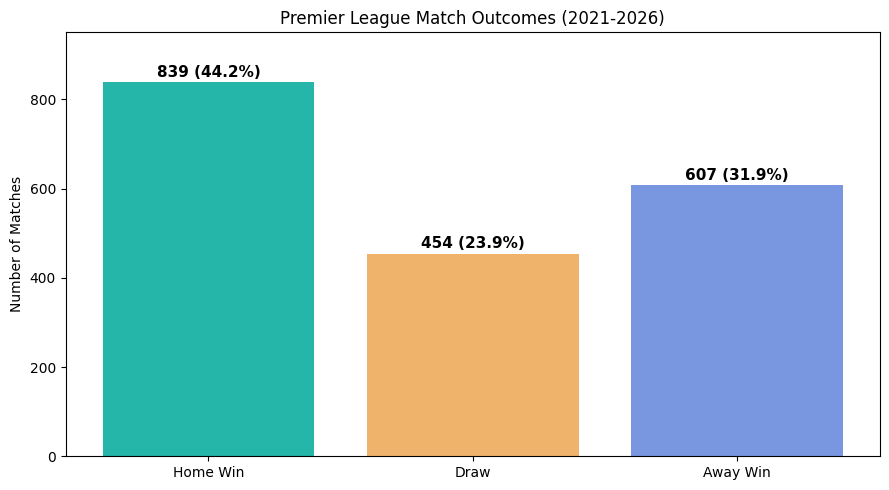

In [18]:

# Count match results
results = ["H", "D", "A"]
labels = ["Home Win", "Draw", "Away Win"]

counts = df["FTR"].value_counts().reindex(results)

# Create chart
fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    labels,
    counts.values,
    color=["#25B5A9", "#F0B36B", "#7996E0"]
)

ax.set_title("Premier League Match Outcomes (2021-2026)")
ax.set_ylabel("Number of Matches")
ax.set_ylim(0, 950)

# Add match counts and percentages
for bar, count in zip(bars, counts.values):
    percentage = count / len(df) * 100

    ax.text(
        bar.get_x() + bar.get_width()/2,
        count + 12,
        f"{count} ({percentage:.1f}%)",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

plt.tight_layout()
display(fig)
plt.close(fig)


Match results by season:


FTR,H,D,A
Season,,,
2021–22,163,88,129
2022–23,184,87,109
2023–24,175,82,123
2024–25,155,93,132
2025–26,162,104,114


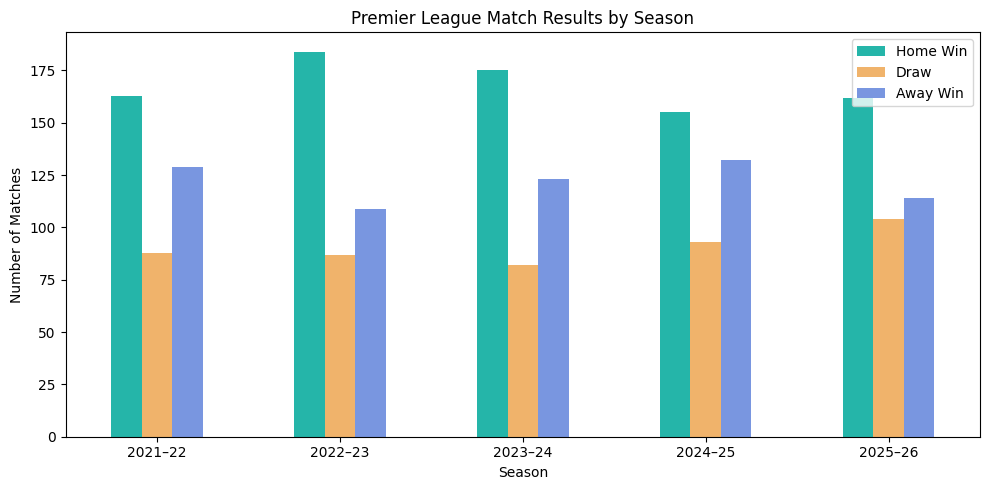

In [19]:

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Count home wins, draws, and away wins for each season
season_results = pd.crosstab(df["Season"], df["FTR"])

# Arrange the results
season_results = season_results[["H", "D", "A"]]

print("Match results by season:")
display(season_results)

# Create the chart
fig, ax = plt.subplots(figsize=(10, 5))

season_results.plot(
    kind="bar",
    ax=ax,
    color=["#25B5A9", "#F0B36B", "#7996E0"]
)

ax.set_title("Premier League Match Results by Season")
ax.set_xlabel("Season")
ax.set_ylabel("Number of Matches")
ax.legend(["Home Win", "Draw", "Away Win"])
ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
display(fig)
plt.close(fig)


In [20]:

# Essential columns needed for our project
important_columns = [
    "Date",
    "HomeTeam",
    "AwayTeam",
    "FTHG",
    "FTAG",
    "FTR"
]

# Check for missing values
missing = df[important_columns].isnull().sum()

print("Missing values:")
print(missing)

# Check for duplicate match records
duplicates = df.duplicated(
    subset=["Season", "Date", "HomeTeam", "AwayTeam"]
).sum()

print("\nDuplicate matches:", duplicates)

# Show total rows
print("\nTotal matches:", len(df))


Missing values:
Date        0
HomeTeam    0
AwayTeam    0
FTHG        0
FTAG        0
FTR         0
dtype: int64

Duplicate matches: 0

Total matches: 1900


In [23]:

# Get Arsenal's first 6 matches
arsenal = df[
    (df["HomeTeam"] == "Arsenal") |
    (df["AwayTeam"] == "Arsenal")
].head(6).copy()

# Use only the first 5 matches
previous_5 = arsenal.head(5)

goals_scored = 0
goals_conceded = 0
points = 0
wins = 0

for _, match in previous_5.iterrows():

    if match["HomeTeam"] == "Arsenal":
        scored = match["FTHG"]
        conceded = match["FTAG"]
    else:
        scored = match["FTAG"]
        conceded = match["FTHG"]

    goals_scored += scored
    goals_conceded += conceded

    if scored > conceded:
        points += 3
        wins += 1
    elif scored == conceded:
        points += 1

print("Arsenal's previous 5 matches:")
print("Goals scored:", goals_scored)
print("Goals conceded:", goals_conceded)
print("Points earned:", points)
print("Wins:", wins)
print("Average goals scored:", goals_scored / 5)
print("Average goals conceded:", goals_conceded / 5)


Arsenal's previous 5 matches:
Goals scored: 2
Goals conceded: 9
Points earned: 6
Wins: 2
Average goals scored: 0.4
Average goals conceded: 1.8


In [25]:

# Find Tottenham matches without the season filter
tottenham = df[
    (df["HomeTeam"] == "Tottenham") |
    (df["AwayTeam"] == "Tottenham")
].head(5).copy()

print("Number of matches found:", len(tottenham))

print("\nTottenham's first 5 matches:")
display(tottenham)


Number of matches found: 5

Tottenham's first 5 matches:


,Date,HomeTeam,AwayTeam,FTHG,FTAG,FTR,Season
9,15/08/2021,Tottenham,Man City,1,0,H,2021–22
17,22/08/2021,Wolves,Tottenham,0,1,A,2021–22
28,29/08/2021,Tottenham,Watford,1,0,H,2021–22
30,11/09/2021,Crystal Palace,Tottenham,3,0,H,2021–22
49,19/09/2021,Tottenham,Chelsea,0,3,A,2021–22


In [26]:

goals_scored = 0
goals_conceded = 0
points = 0
wins = 0

for _, match in tottenham.iterrows():

    if match["HomeTeam"] == "Tottenham":
        scored = match["FTHG"]
        conceded = match["FTAG"]
    else:
        scored = match["FTAG"]
        conceded = match["FTHG"]

    goals_scored += scored
    goals_conceded += conceded

    if scored > conceded:
        points += 3
        wins += 1
    elif scored == conceded:
        points += 1

print("Tottenham's previous 5 matches:")
print("Goals scored:", goals_scored)
print("Goals conceded:", goals_conceded)
print("Points earned:", points)
print("Wins:", wins)
print("Average goals scored:", goals_scored / 5)
print("Average goals conceded:", goals_conceded / 5)


Tottenham's previous 5 matches:
Goals scored: 3
Goals conceded: 6
Points earned: 9
Wins: 3
Average goals scored: 0.6
Average goals conceded: 1.2


In [27]:

# Arsenal's previous 5 match statistics
arsenal_goals = 2
arsenal_conceded = 9
arsenal_points = 6
arsenal_wins = 2

# Tottenham's previous 5 match statistics
tottenham_goals = 3
tottenham_conceded = 6
tottenham_points = 9
tottenham_wins = 3

# Calculate home team minus away team
goals_difference = arsenal_goals - tottenham_goals
conceded_difference = arsenal_conceded - tottenham_conceded
points_difference = arsenal_points - tottenham_points
wins_difference = arsenal_wins - tottenham_wins

print("Arsenal vs Tottenham — Feature Differences")
print("-----------------------------------------")
print("Goals scored difference:", goals_difference)
print("Goals conceded difference:", conceded_difference)
print("Points difference:", points_difference)
print("Wins difference:", wins_difference)


Arsenal vs Tottenham — Feature Differences
-----------------------------------------
Goals scored difference: -1
Goals conceded difference: 3
Points difference: -3
Wins difference: -1


In [28]:

import os

print("Files available in Google Colab:")
for filename in sorted(os.listdir()):
    if filename.endswith(".csv"):
        print(filename)


Files available in Google Colab:
EPL_Combined_1900_Matches (2).csv
EPL_Combined_1900_Matches.csv
EPL_Logistic_Confusion_Matrix.csv
EPL_Model_Results.csv
EPL_PreMatch_Features.csv


In [29]:

import pandas as pd

# Load the feature-engineered dataset
features = pd.read_csv("EPL_PreMatch_Features.csv")

print("Total original matches:", len(df))
print("Matches in feature dataset:", len(features))

print("\nColumns in feature dataset:")
print(features.columns.tolist())

print("\nFirst 5 rows:")
display(features.head())


Total original matches: 1900
Matches in feature dataset: 1815

Columns in feature dataset:
['Date', 'Season', 'HomeTeam', 'AwayTeam', 'FTR', 'home_n', 'home_points_5', 'home_gf_5', 'home_ga_5', 'home_win_5', 'away_n', 'away_points_5', 'away_gf_5', 'away_ga_5', 'away_win_5', 'diff_points_5', 'diff_gf_5', 'diff_ga_5', 'diff_win_5']

First 5 rows:


,Date,Season,HomeTeam,AwayTeam,FTR,home_n,home_points_5,home_gf_5,home_ga_5,home_win_5,away_n,away_points_5,away_gf_5,away_ga_5,away_win_5,diff_points_5,diff_gf_5,diff_ga_5,diff_win_5
0,2021-09-25,2021–22,Brentford,Liverpool,D,5,1.6,1.0,0.4,0.4,5,2.6,2.4,0.2,0.8,-1.0,-1.4,0.2,-0.4
1,2021-09-25,2021–22,Chelsea,Man City,A,5,2.6,2.4,0.2,0.8,5,2.0,2.2,0.2,0.6,0.6,0.2,0.0,0.2
2,2021-09-25,2021–22,Everton,Norwich,H,5,2.0,2.0,1.4,0.6,5,0.0,0.4,2.8,0.0,2.0,1.6,-1.4,0.6
3,2021-09-25,2021–22,Leeds,West Ham,A,5,0.6,1.0,2.4,0.0,5,1.6,2.2,1.4,0.4,-1.0,-1.2,1.0,-0.4
4,2021-09-25,2021–22,Leicester,Burnley,D,5,1.2,1.0,1.6,0.4,5,0.2,0.6,1.8,0.0,1.0,0.4,-0.2,0.4


In [31]:

# Select the testing season using its starting year
test = features[
    features["Season"].str.startswith("2025")
].copy()

# All earlier seasons are training data
train = features[
    ~features["Season"].str.startswith("2025")
].copy()

print("Training matches:", len(train))
print("Testing matches:", len(test))
print("Total usable matches:", len(train) + len(test))

print("\nTraining seasons:")
print(train["Season"].unique())

print("\nTesting season:")
print(test["Season"].unique())


Training matches: 1440
Testing matches: 375
Total usable matches: 1815

Training seasons:
['2021–22' '2022–23' '2023–24' '2024–25']

Testing season:
['2025–26']


In [32]:

from sklearn.metrics import accuracy_score

# Find the most common result in training data
most_common = train["FTR"].mode()[0]

print("Most common training result:", most_common)

# Predict the same result for every test match
baseline_predictions = [most_common] * len(test)

# Compare predictions with actual results
correct = sum(
    prediction == actual
    for prediction, actual in zip(
        baseline_predictions, test["FTR"]
    )
)

accuracy = accuracy_score(
    test["FTR"],
    baseline_predictions
)

print("Correct predictions:", correct)
print("Total test matches:", len(test))
print("Baseline accuracy:", round(accuracy * 100, 1), "%")


Most common training result: H
Correct predictions: 159
Total test matches: 375
Baseline accuracy: 42.4 %


In [36]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

# Select the same features as the original script
model_features = [
    c for c in features.columns
    if c.startswith(("home_", "away_", "diff_"))
    and c not in ["home_n", "away_n"]
]

# Use the same date-based training/testing split
train_exact = features[
    features["Date"] < "2025-08-01"
]

test_exact = features[
    features["Date"] >= "2025-08-01"
]

X_train = train_exact[model_features]
y_train = train_exact["FTR"]

X_test = test_exact[model_features]
y_test = test_exact["FTR"]

# Train the original Logistic Regression model
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=1000,
        random_state=42
    )
)

logistic_model.fit(X_train, y_train)

# Make predictions
logistic_predictions = logistic_model.predict(X_test)

# Calculate results
correct = (logistic_predictions == y_test).sum()
accuracy = accuracy_score(y_test, logistic_predictions)
macro_f1 = f1_score(
    y_test,
    logistic_predictions,
    average="macro"
)

print("Features used:", len(model_features))
print("Training matches:", len(train_exact))
print("Testing matches:", len(test_exact))
print()
print("Correct predictions:", correct)
print("Accuracy:", round(accuracy * 100, 1), "%")
print("Macro F1:", round(macro_f1, 4))


Features used: 12
Training matches: 1440
Testing matches: 375

Correct predictions: 175
Accuracy: 46.7 %
Macro F1: 0.3514


In [40]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score

# Create Random Forest with original settings
rf_model = RandomForestClassifier(
    n_estimators=300,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Train using the same 1,440 matches
rf_model.fit(X_train, y_train)

# Predict the same 375 test matches
rf_predictions = rf_model.predict(X_test)

# Calculate performance
rf_correct = (rf_predictions == y_test).sum()

rf_accuracy = accuracy_score(
    y_test,
    rf_predictions
)

rf_macro_f1 = f1_score(
    y_test,
    rf_predictions,
    average="macro"
)

print("Random Forest Results")
print("---------------------")
print("Correct predictions:", rf_correct)
print("Total test matches:", len(y_test))
print("Accuracy:", round(rf_accuracy * 100, 1), "%")
print("Macro F1:", round(rf_macro_f1, 4))


Random Forest Results
---------------------
Correct predictions: 171
Total test matches: 375
Accuracy: 45.6 %
Macro F1: 0.3452


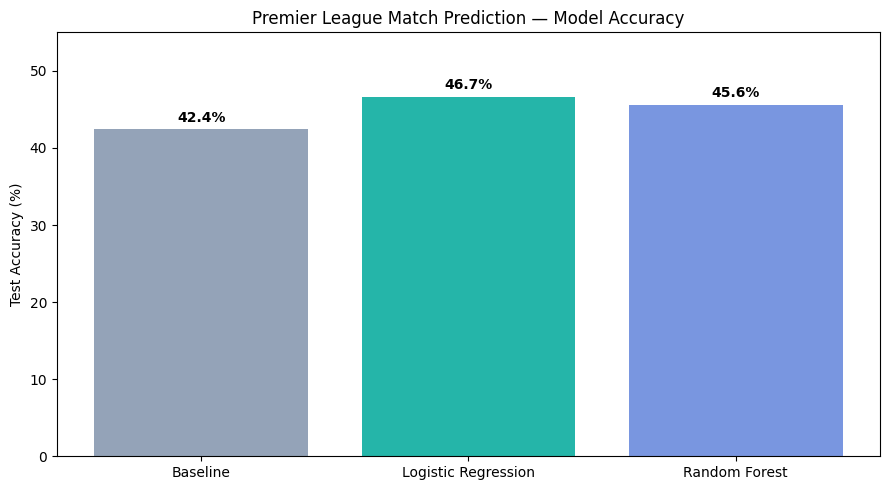

In [41]:

import matplotlib.pyplot as plt
from IPython.display import display

models = [
    "Baseline",
    "Logistic Regression",
    "Random Forest"
]

accuracies = [
    159 / 375 * 100,
    175 / 375 * 100,
    171 / 375 * 100
]

fig, ax = plt.subplots(figsize=(9, 5))

bars = ax.bar(
    models,
    accuracies,
    color=["#94A3B8", "#25B5A9", "#7996E0"]
)

ax.set_title("Premier League Match Prediction — Model Accuracy")
ax.set_ylabel("Test Accuracy (%)")
ax.set_ylim(0, 55)

for bar, accuracy in zip(bars, accuracies):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.1f}%",
        ha="center",
        fontweight="bold"
    )

plt.tight_layout()
display(fig)
plt.close(fig)


Logistic Regression Confusion Matrix:


,Predicted Home,Predicted Draw,Predicted Away
Actual Home,123,0,36
Actual Draw,72,1,29
Actual Away,62,1,51


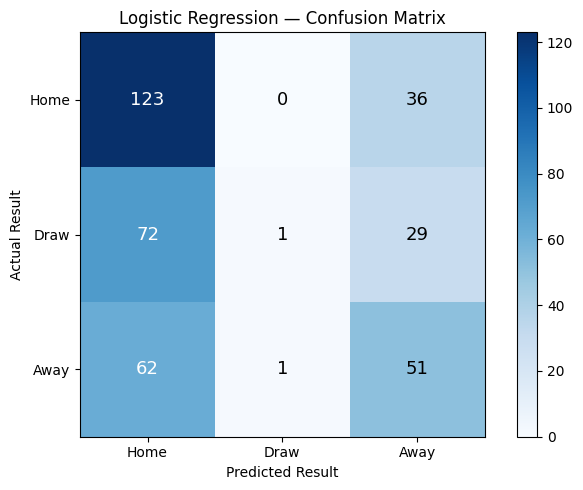

In [42]:

from sklearn.metrics import confusion_matrix
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Compare actual results with Logistic Regression predictions
labels = ["H", "D", "A"]

cm = confusion_matrix(
    y_test,
    logistic_predictions,
    labels=labels
)

# Display the numbers as a table
cm_table = pd.DataFrame(
    cm,
    index=["Actual Home", "Actual Draw", "Actual Away"],
    columns=["Predicted Home", "Predicted Draw", "Predicted Away"]
)

print("Logistic Regression Confusion Matrix:")
display(cm_table)

# Create the chart
fig, ax = plt.subplots(figsize=(7, 5))

image = ax.imshow(cm, cmap="Blues")

ax.set_xticks(range(3), ["Home", "Draw", "Away"])
ax.set_yticks(range(3), ["Home", "Draw", "Away"])

ax.set_xlabel("Predicted Result")
ax.set_ylabel("Actual Result")
ax.set_title("Logistic Regression — Confusion Matrix")

for i in range(3):
    for j in range(3):
        ax.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black",
            fontsize=13
        )

plt.colorbar(image, ax=ax)
plt.tight_layout()
display(fig)
plt.close(fig)


In [43]:

import pandas as pd

# Count actual match results
actual_counts = pd.Series(y_test).value_counts()

# Count Logistic Regression predictions
predicted_counts = pd.Series(logistic_predictions).value_counts()

comparison = pd.DataFrame({
    "Actual Matches": actual_counts,
    "Model Predictions": predicted_counts
}).reindex(["H", "D", "A"])

comparison.index = ["Home Win", "Draw", "Away Win"]

print("Actual Results vs Model Predictions:")
display(comparison)


Actual Results vs Model Predictions:


,Actual Matches,Model Predictions
Home Win,159,257
Draw,102,2
Away Win,114,116
